In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Q1.Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully.")
print(df.head())

Dataset loaded successfully.
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [3]:
## Q2.Display first five records
print("First five records:")
display(df.head())

# Display last five records
print("Last five records:")
display(df.tail())

First five records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Last five records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [4]:
# Q3.# Display dataset information
print("Dataset Information:")
df.info()

# Display descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Descriptive Statistics:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
# Q4.# Independent/input variables
X = df.drop("MedHouseVal", axis=1)

# Dependent/output variable
y = df["MedHouseVal"]

print("Input variables:")
print(X.columns.tolist())

print("\nOutput variable:")
print("MedHouseVal")

Input variables:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Output variable:
MedHouseVal


In [6]:
# Q5.# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [7]:
# Q6.# Select one independent variable
X_simple = df[["MedInc"]]

# Target variable
y_simple = df["MedHouseVal"]

# Split the data
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

# Create Linear Regression model
simple_model = LinearRegression()

print("Simple Linear Regression model created successfully.")

Simple Linear Regression model created successfully.


In [8]:
# Q7.# Train the simple linear regression model
simple_model.fit(X_train_simple, y_train_simple)

print("Model trained successfully.")

Model trained successfully.


In [9]:
# Q8.# Predict values using the trained model
y_pred_simple = simple_model.predict(X_test_simple)

print("First 10 predicted values:")
print(y_pred_simple[:10])

First 10 predicted values:
[1.14958917 1.50606882 1.90393718 2.85059383 2.00663318 2.42165249
 2.57647226 1.99229181 2.45893168 3.84677436]


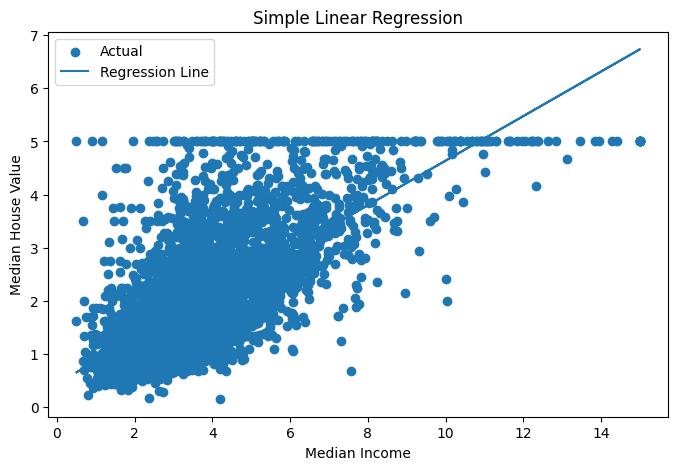

In [10]:
# Q9. Visualize the Linear Regression line
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_simple["MedInc"],
    y_test_simple,
    label="Actual"
)

plt.plot(
    X_test_simple["MedInc"],
    y_pred_simple,
    label="Regression Line"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [11]:
# Q10. Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual": y_test_simple.values,
    "Predicted": y_pred_simple
})

display(comparison.head(10))

,Actual,Predicted
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


In [12]:
# Q11. Display regression coefficient and intercept
print("Regression Coefficient:")
print(simple_model.coef_[0])

print("\nIntercept:")
print(simple_model.intercept_)

Regression Coefficient:
0.4193384939381274

Intercept:
0.44459729169078677


In [14]:
# Q12. Predict output for new user-defined input

new_income = pd.DataFrame({
    "MedInc": [5.0]
})

# Prediction
new_prediction = simple_model.predict(new_income)

print("Predicted house value:", new_prediction[0])

Predicted house value: 2.5412897613814236


In [15]:
# Q13. Implement Multiple Linear Regression

X = df.drop("MedHouseVal", axis=1)

# Output variable
y = df["MedHouseVal"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create model
multiple_model = LinearRegression()

print("Multiple Linear Regression model created.")

Multiple Linear Regression model created.


In [16]:
# Q14. Train Multiple Linear Regression model

multiple_model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully.")

Multiple Linear Regression model trained successfully.


In [17]:
# 15. Predict output using testing dataset

y_pred_multiple = multiple_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_multiple[:10])

First 10 predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


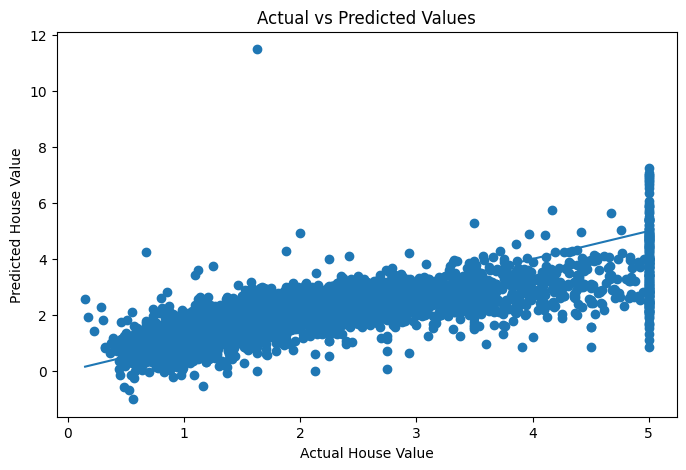

In [18]:
# Q16. Compare actual and predicted values graphically
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred_multiple
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted Values")

# Reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.show()

In [19]:
# Q17. Analyze the effect of each independent variable

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": multiple_model.coef_
})

display(coefficients.sort_values(
    by="Coefficient",
    ascending=False
))

,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
1,HouseAge,0.009724
4,Population,-0.000002
5,AveOccup,-0.003526
2,AveRooms,-0.123323
6,Latitude,-0.419792
7,Longitude,-0.433708


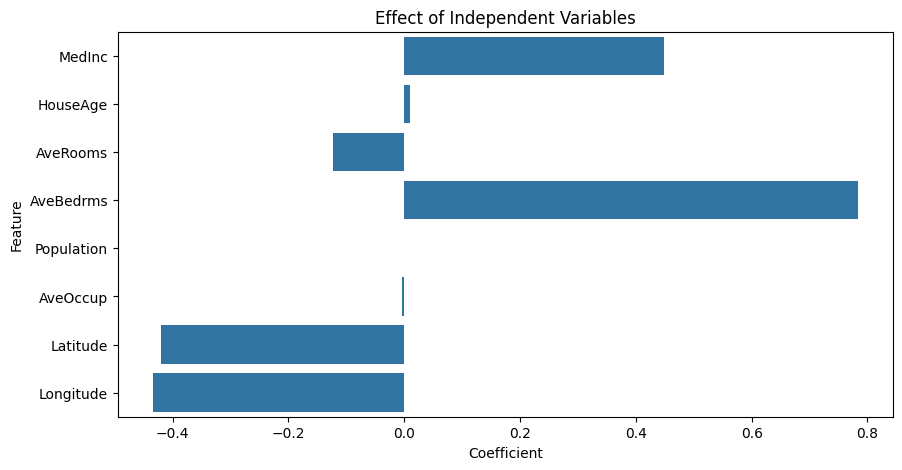

In [20]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Effect of Independent Variables")
plt.show()

In [21]:
# Q18. Implement Polynomial Regression of Degree 2

X_poly = df[["MedInc"]]
y_poly = df["MedHouseVal"]

# Split data
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_poly,
    y_poly,
    test_size=0.2,
    random_state=42
)

# Create polynomial regression degree 2
poly2_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

# Train
poly2_model.fit(X_train_poly, y_train_poly)

# Predict
y_pred_poly2 = poly2_model.predict(X_test_poly)

print("Degree 2 Polynomial Regression completed.")

Degree 2 Polynomial Regression completed.


In [22]:
# Q19. Implement Polynomial Regression of Degree 3

poly3_model = make_pipeline(
    PolynomialFeatures(degree=3),
    LinearRegression()
)

# Train model
poly3_model.fit(X_train_poly, y_train_poly)

# Predict
y_pred_poly3 = poly3_model.predict(X_test_poly)

print("Degree 3 Polynomial Regression completed.")

Degree 3 Polynomial Regression completed.


In [23]:
# Q20. Compare Linear and Polynomial Regression

y_pred_linear = simple_model.predict(X_test_simple)

# Calculate R2 scores
linear_r2 = r2_score(y_test_simple, y_pred_linear)
poly2_r2 = r2_score(y_test_poly, y_pred_poly2)
poly3_r2 = r2_score(y_test_poly, y_pred_poly3)

comparison_models = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Degree 2",
        "Polynomial Degree 3"
    ],
    "R2 Score": [
        linear_r2,
        poly2_r2,
        poly3_r2
    ]
})

display(comparison_models)

,Model,R2 Score
0,Linear Regression,0.458859
1,Polynomial Degree 2,0.463318
2,Polynomial Degree 3,0.467116


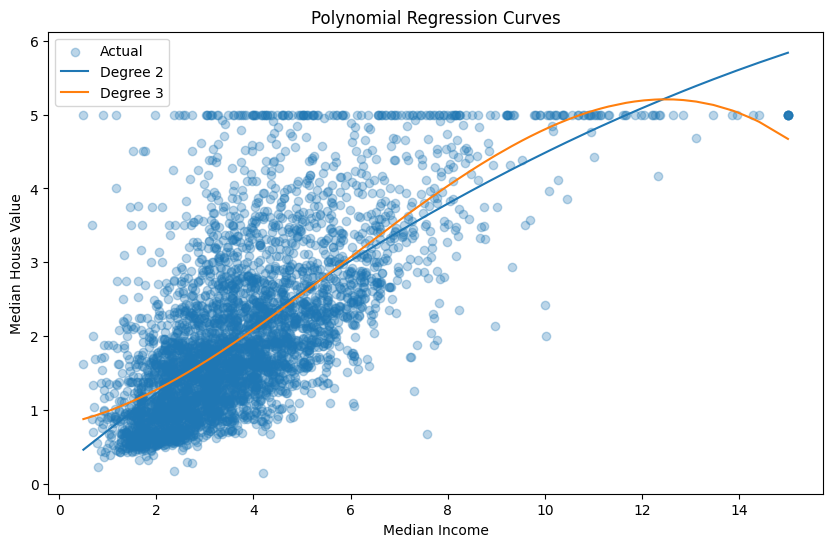

In [24]:
# Q21. Visualize Polynomial Regression curves

sorted_indices = np.argsort(X_test_poly["MedInc"].values)

X_sorted = X_test_poly.iloc[sorted_indices]

y_poly2_sorted = y_pred_poly2[sorted_indices]
y_poly3_sorted = y_pred_poly3[sorted_indices]

plt.figure(figsize=(10, 6))

plt.scatter(
    X_test_poly["MedInc"],
    y_test_poly,
    alpha=0.3,
    label="Actual"
)

plt.plot(
    X_sorted["MedInc"],
    y_poly2_sorted,
    label="Degree 2"
)

plt.plot(
    X_sorted["MedInc"],
    y_poly3_sorted,
    label="Degree 3"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Polynomial Regression Curves")
plt.legend()
plt.show()

In [25]:
# Q22. Predict output using Polynomial Regression
# User-defined input
new_income = pd.DataFrame({
    "MedInc": [5.0]
})

# Degree 2 prediction
prediction_degree2 = poly2_model.predict(new_income)

# Degree 3 prediction
prediction_degree3 = poly3_model.predict(new_income)

print("Degree 2 prediction:", prediction_degree2[0])
print("Degree 3 prediction:", prediction_degree3[0])

Degree 2 prediction: 2.6028228883087863
Degree 3 prediction: 2.571562374519795


In [26]:
# Q23. Compare prediction accuracy for different polynomial degrees
degrees = [1, 2, 3, 4]

results = []

for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(X_train_poly, y_train_poly)

    prediction = model.predict(X_test_poly)

    mae = mean_absolute_error(y_test_poly, prediction)
    mse = mean_squared_error(y_test_poly, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_poly, prediction)

    results.append([
        degree,
        mae,
        mse,
        rmse,
        r2
    ])

degree_results = pd.DataFrame(
    results,
    columns=["Degree", "MAE", "MSE", "RMSE", "R2"]
)

display(degree_results)

,Degree,MAE,MSE,RMSE,R2
0,1,0.629909,0.709116,0.842090,0.458859
1,2,0.628292,0.703273,0.838614,0.463318
2,3,0.621896,0.698296,0.835641,0.467116
3,4,0.621889,0.698104,0.835526,0.467262


In [27]:
# Q24. Calculate Mean Absolute Error (MAE)

mae = mean_absolute_error(
    y_test,
    y_pred_multiple
)

print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 0.5332001304956557


In [28]:
# Q25. Calculate Mean Squared Error (MSE)
mse = mean_squared_error(
    y_test,
    y_pred_multiple
)

print("Mean Squared Error (MSE):", mse)

Mean Squared Error (MSE): 0.5558915986952435


In [29]:
# Q26. Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 0.7455813830127758


In [30]:
# Q27. Calculate R-squared Score
r2 = r2_score(
    y_test,
    y_pred_multiple
)

print("R-squared (R²) Score:", r2)

R-squared (R²) Score: 0.5757877060324514


In [31]:
# Q28. Compare Linear and Polynomial Regression using evaluation metrics
# Linear Regression
linear_mae = mean_absolute_error(
    y_test_simple,
    y_pred_linear
)

linear_mse = mean_squared_error(
    y_test_simple,
    y_pred_linear
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    y_test_simple,
    y_pred_linear
)


# Polynomial Degree 2
poly2_mae = mean_absolute_error(
    y_test_poly,
    y_pred_poly2
)

poly2_mse = mean_squared_error(
    y_test_poly,
    y_pred_poly2
)

poly2_rmse = np.sqrt(poly2_mse)

poly2_r2 = r2_score(
    y_test_poly,
    y_pred_poly2
)


# Polynomial Degree 3
poly3_mae = mean_absolute_error(
    y_test_poly,
    y_pred_poly3
)

poly3_mse = mean_squared_error(
    y_test_poly,
    y_pred_poly3
)

poly3_rmse = np.sqrt(poly3_mse)

poly3_r2 = r2_score(
    y_test_poly,
    y_pred_poly3
)


metrics_comparison = pd.DataFrame({
    "Model": [
        "Linear",
        "Polynomial Degree 2",
        "Polynomial Degree 3"
    ],
    "MAE": [
        linear_mae,
        poly2_mae,
        poly3_mae
    ],
    "MSE": [
        linear_mse,
        poly2_mse,
        poly3_mse
    ],
    "RMSE": [
        linear_rmse,
        poly2_rmse,
        poly3_rmse
    ],
    "R2": [
        linear_r2,
        poly2_r2,
        poly3_r2
    ]
})

display(metrics_comparison)

,Model,MAE,MSE,RMSE,R2
0,Linear,0.629909,0.709116,0.842090,0.458859
1,Polynomial Degree 2,0.628292,0.703273,0.838614,0.463318
2,Polynomial Degree 3,0.621896,0.698296,0.835641,0.467116


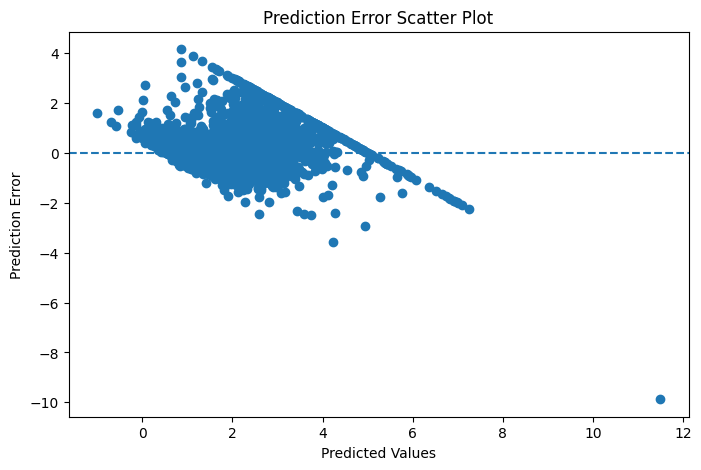

In [33]:
# Q30. Visualize prediction errors using scatter plot
# Calculate prediction errors
errors = y_test - y_pred_multiple

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_multiple,
    errors
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Values")
plt.ylabel("Prediction Error")
plt.title("Prediction Error Scatter Plot")

plt.show()

In [35]:
# Q31. Train regression model using standardized features

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create pipeline with StandardScaler and LinearRegression
scaled_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Train model
scaled_model.fit(X_train, y_train)

# Predict
y_pred_scaled = scaled_model.predict(X_test)

print("Standardized regression model trained successfully.")

Standardized regression model trained successfully.


In [36]:
# Q32. Compare model performance before and after feature scaling
# Original model predictions
y_pred_original = multiple_model.predict(X_test)

# Original model metrics
original_mae = mean_absolute_error(y_test, y_pred_original)
original_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_original)
)
original_r2 = r2_score(y_test, y_pred_original)

# Scaled model metrics
scaled_mae = mean_absolute_error(y_test, y_pred_scaled)
scaled_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_scaled)
)
scaled_r2 = r2_score(y_test, y_pred_scaled)

scaling_comparison = pd.DataFrame({
    "Model": [
        "Before Scaling",
        "After Scaling"
    ],
    "MAE": [
        original_mae,
        scaled_mae
    ],
    "RMSE": [
        original_rmse,
        scaled_rmse
    ],
    "R2": [
        original_r2,
        scaled_r2
    ]
})

display(scaling_comparison)

,Model,MAE,RMSE,R2
0,Before Scaling,0.5332,0.745581,0.575788
1,After Scaling,0.5332,0.745581,0.575788


In [38]:
#  Q33. Perform regression using another real-world dataset

from sklearn.datasets import load_diabetes

# Load Diabetes dataset
diabetes = load_diabetes(as_frame=True)

diabetes_df = diabetes.frame

print("Diabetes dataset:")
display(diabetes_df.head())

print("\nDataset shape:")
print(diabetes_df.shape)

Diabetes dataset:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Dataset shape:
(442, 11)


In [39]:
# Separate input and target
X_diabetes = diabetes_df.drop("target", axis=1)
y_diabetes = diabetes_df["target"]

# Split data
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_diabetes,
    y_diabetes,
    test_size=0.2,
    random_state=42
)

# Create model
diabetes_model = LinearRegression()

# Train
diabetes_model.fit(X_train_d, y_train_d)

# Predict
y_pred_d = diabetes_model.predict(X_test_d)

# Evaluate
diabetes_mae = mean_absolute_error(
    y_test_d,
    y_pred_d
)

diabetes_rmse = np.sqrt(
    mean_squared_error(y_test_d, y_pred_d)
)

diabetes_r2 = r2_score(
    y_test_d,
    y_pred_d
)

print("MAE:", diabetes_mae)
print("RMSE:", diabetes_rmse)
print("R²:", diabetes_r2)

MAE: 42.79409467959994
RMSE: 53.85344583676591
R²: 0.4526027629719198


In [40]:
# Q34. Save the trained regression model using Joblib

joblib.dump(
    multiple_model,
    "linear_regression_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [41]:
# Q35. Load the saved model and predict new data

loaded_model = joblib.load(
    "linear_regression_model.pkl"
)

print("Model loaded successfully.")

Model loaded successfully.


In [42]:
# Create new housing input
new_house = pd.DataFrame({
    "MedInc": [5.0],
    "HouseAge": [30.0],
    "AveRooms": [6.0],
    "AveBedrms": [1.0],
    "Population": [1000.0],
    "AveOccup": [3.0],
    "Latitude": [34.0],
    "Longitude": [-118.0]
})

# Predict house value
prediction = loaded_model.predict(new_house)

print("Predicted House Value:", prediction[0])

Predicted House Value: 2.4470279633315712
